# Exp03-Part1-t1.基于残差网络的手写体数字识别（Paddle）

In [ ]:
import paddle
import paddle.nn.functional as F
from paddle.vision.transforms import ToTensor
import numpy as np
import matplotlib.pyplot as plt

print(paddle.__version__)

# 1.准备数据

## 1.1 数据集简介

手写体数字识别是计算机视觉中最常用的图像分类任务，让计算机识别出给定图片中的手写体数字（0-9共10个数字）。由于手写体风格差异很大，因此手写体数字识别是具有一定难度的任务。

我们采用常用的手写数字识别数据集：**MNIST数据集**。MNIST数据集是计算机视觉领域的经典入门数据集，包含了60,000个训练样本和10,000个测试样本。这些数字已经过尺寸标准化并位于图像中心，图像是固定大小($28\times28$像素)。**图1**给出了部分样本的示例。

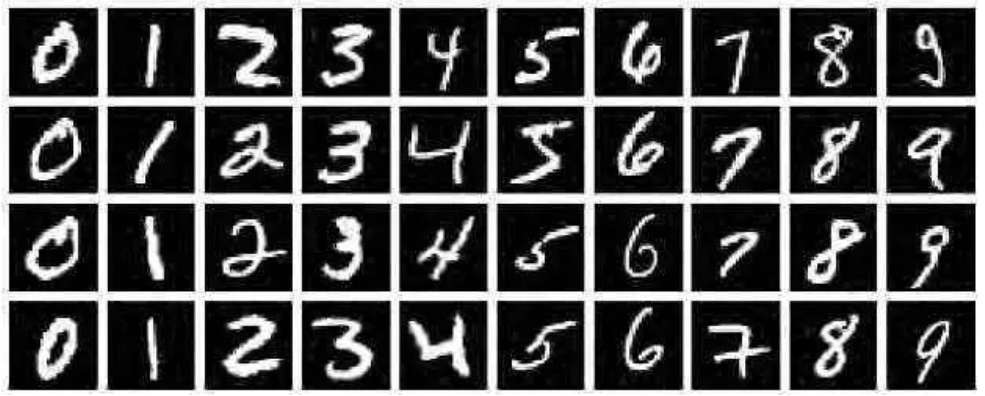

<center>图1 MNIST数据集</center>

为了节省训练时间，本节选取MNIST数据集的一个子集进行后续实践，数据集的划分为：

* 训练集：1,000条样本
* 验证集：200条样本
* 测试集：200条样本

MNIST数据集分为train_set、dev_set和test_set三个数据集，每个数据集含两个列表分别存放了图片数据以及标签数据。比如train_set包含：

* **图片数据**：[1 000, 784]的二维列表，包含1 000张图片。每张图片用一个长度为784的向量表示，内容是 $28\times 28$ 尺寸的像素灰度值（黑白图片）。
* **标签数据**：[1 000, 1]的列表，表示这些图片对应的分类标签，即0~9之间的数字。

In [ ]:
import json
import gzip

# 打印并观察数据集分布情况
train_set, dev_set, test_set = json.load(gzip.open('./mnist.json.gz'))
train_images, train_labels = train_set[0][:1000], train_set[1][:1000]
dev_images, dev_labels = dev_set[0][:200], dev_set[1][:200]
test_images, test_labels = test_set[0][:200], test_set[1][:200]
train_set, dev_set, test_set = [train_images, train_labels], [dev_images, dev_labels], [test_images, test_labels]
print('Length of train/dev/test set:{}/{}/{}'.format(len(train_set[0]), len(dev_set[0]), len(test_set[0])))

可视化观察其中的一张样本以及对应的标签，代码如下所示：

In [ ]:
from PIL import Image

image, label = train_set[0][0], train_set[1][0]
image, label = np.array(image).astype('float32'), int(label)
# 原始图像数据为长度784的行向量，需要调整为[28,28]大小的图像
image = np.reshape(image, [28,28])
image = Image.fromarray(image.astype('uint8'), mode='L')
print("The number in the picture is {}".format(label))
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.savefig('conv-number5.pdf')
# print("train_set[0][0]:", train_set[0][0])
# print("train_set[1][0]:", train_set[1][0])

## 1.2 数据预处理

图像分类网络对输入图片的格式、大小有一定的要求，数据输入模型前，需要对数据进行预处理操作，使图片满足网络训练以及预测的需要。本实践主要应用了如下方法：

*  调整图片大小：LeNet网络对输入图片大小的要求为 $32\times 32$ ，而MNIST数据集中的原始图片大小却是 $28\times 28$ ，这里为了符合网络的结构设计，将其调整为$32 \times 32$；
*  规范化： 通过规范化手段，把输入图像的分布改变成均值为0，标准差为1的标准正态分布，使得最优解的寻优过程明显会变得平缓，训练过程更容易收敛。

*******

在飞桨中，提供了部分视觉领域的高层API，可以直接调用API实现简单的图像处理操作。通过调用`paddle.vision.transforms.Resize`调整大小；调用`paddle.vision.transforms.Normalize`进行标准化处理；使用`paddle.vision.transforms.Compose`将两个预处理操作进行拼接。

*******

代码实现如下：

In [ ]:
from paddle.vision.transforms import Compose, Resize, Normalize

# 数据预处理
transforms = Compose([Resize(32), Normalize(mean=[127.5], std=[127.5], data_format='CHW')])

将原始的数据集封装为Dataset类，以便DataLoader调用。

In [ ]:
import random
import paddle.io as io

class MNIST_dataset(io.Dataset):
    def __init__(self, dataset, transforms, mode='train'):
        self.mode = mode
        self.transforms =transforms
        self.dataset = dataset

    def __getitem__(self, idx):
        # 获取图像和标签
        image, label = self.dataset[0][idx], self.dataset[1][idx]
        image, label = np.array(image).astype('float32'), int(label)
        image = np.reshape(image, [28,28])
        image = Image.fromarray(image.astype('uint8'), mode='L')  # 如果数组是二维的，并且数据类型为 uint8，则默认创建一个灰度图像（模式 'L'）
        image = self.transforms(image)

        return image, label

    def __len__(self):
        return len(self.dataset[0])

In [ ]:
# 固定随机种子
random.seed(0)
# 加载 mnist 数据集
train_dataset = MNIST_dataset(dataset=train_set, transforms=transforms, mode='train')
test_dataset = MNIST_dataset(dataset=test_set, transforms=transforms, mode='test')
dev_dataset = MNIST_dataset(dataset=dev_set, transforms=transforms, mode='dev')
tmp = test_dataset.__getitem__(0)
print(tmp[0].shape, tmp)

# 2.模型构建

## 2.1 相关类说明

### 2.1.1 paddle.nn.Conv2D二维卷积层

`paddle.nn.Conv2D` 是 PaddlePaddle 深度学习框架中的一个核心层，用于构建二维卷积神经网络（2D Convolutional Neural Networks）。这个层主要用于处理图像数据，通过卷积操作提取图像的特征。 

__`class paddle.nn.Conv2D(in_channels, out_channels, kernel_size, stride=1, padding=0, dilation=1, groups=1, padding_mode='zeros', weight_attr=None, bias_attr=None, data_format='NCHW')`__

`paddle.nn.Conv2D` 根据输入、卷积核、步长（stride）、填充（padding）、空洞大小（dilations）一组参数计算输出特征层大小。输入和输出是 NCHW 或 NHWC 格式，其中 N 是批尺寸，C 是通道数，H 是特征高度，W 是特征宽度。卷积核是 MCHW 格式，M 是输出图像通道数，C 是输入图像通道数，H 是卷积核高度，W 是卷积核宽度。

当创建一个 `paddle.nn.Conv2D` 层时，需要指定一些参数：

* in_channels：输入数据的通道数。例如，彩色图像的通道数为3（红、绿、蓝）。
* out_channels：卷积层输出的通道数，也就是卷积核（或过滤器）的数量。
* kernel_size：卷积核的大小，可以是单个整数或由两个整数组成的元组，分别表示卷积核的高度和宽度。
* stride：卷积时滑动的步长，默认为1。
* padding：在输入数据周围填充的零的层数，默认为0。
* dilation：卷积核元素之间的间距，默认为1。
* groups：连接输入和输出通道的组数，默认为1，当等于 in_channels 且 out_channels 是 in_channels 的倍数时，执行分组卷积，可以减少参数数量。
* weight_attr：卷积核的参数初始化策略。
* bias_attr：偏置项的参数初始化策略。

__<span style="color: red;">paddle.nn.Conv2D官方文档请参考：</span>__ 
https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/nn/Conv2D_cn.html#cn-api-paddle-nn-conv2d


### 2.1.2 paddle.nn.MaxPool2D二维最大池化

`paddle.nn.MaxPool2D` 用于创建一个最大池化层（Max Pooling Layer）。最大池化是一种常用的下采样操作，它可以减少数据的空间尺寸（宽度和高度），同时保留重要的特征信息，从而减少计算量和防止过拟合。
`paddle.nn.MaxPool2D` 通过对输入数据的局部区域进行最大值操作来实现池化。每个局部区域的大小由 kernel_size 参数指定，而区域之间的间隔由 stride 参数控制。

__`paddle.nn.MaxPool2D(kernel_size, stride=None, padding=0, ceil_mode=False, return_mask=False, data_format='NCHW', name=None)`__

主要参数：
* kernel_size：池化窗口的大小，可以是单个整数或由两个整数组成的元组，分别表示池化窗口的高度和宽度。例如，pool_size=2 或 kernel_size=(2, 2) 表示使用2x2的池化窗口。
* stride：池化操作的步长，它决定了池化窗口滑动的间隔。较小的步长会生成更细粒度的特征图，而较大的步长会生成更粗糙的特征图。默认值为 pool_size。
* padding：输入数据边缘的填充量，可以是单个整数或由两个整数组成的元组。填充可以在不改变输出尺寸的情况下，包含输入数据边缘的信息。
* ceil_mode：当输入尺寸不能被 stride 整除时，是否使用向上取整的方式计算输出尺寸。默认为 False，即按正常方式计算输出尺寸。

__<span style="color: red;">paddle.nn.MaxPool2D官方文档请参考：</span>__ 
https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/nn/MaxPool2D_cn.html#cn-api-paddle-nn-maxpool2d

### 2.1.3 paddle.nn.Linear线性变换层（全连接层）

`paddle.nn.Linear` 用于实现全连接层（也称为线性层或密集层）。全连接层是神经网络中最基本的层之一，它的功能是将输入数据进行线性变换，通常用于网络的最后几层，以输出最终的预测结果。

__`class paddle.nn.Linear(in_features, out_features, weight_attr=None, bias_attr=None, name=None)`__


主要参数：
* in_features：输入特征的数量，即输入数据的维度。
* out_features：输出特征的数量，即输出数据的维度。
* bias：一个布尔值，表示是否使用偏置项。默认为 True，即使用偏置项。

全连接层通常用于以下场景：

* 特征融合：在卷积层提取了局部特征后，全连接层可以将这些特征融合起来，为分类或回归任务提供全局信息。
* 分类任务：在图像分类、文本分类等任务中，全连接层通常位于网络的末端，用于根据学习到的特征进行最终的类别预测。
* 回归任务：在回归分析中，全连接层可以用来预测连续的数值输出。

__<span style="color: red;">paddle.nn.Linear官方文档请参考：</span>__ 
https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/nn/Linear_cn.html#cn-api-paddle-nn-linear


### 2.1.4 查看模型参数

`paddle.summary(net, input_size=None, dtypes=None, input=None)`

`paddle.summary` 是 PaddlePaddle 深度学习框架中的一个实用工具，它用于打印和展示模型结构及其参数的详细信息。这个功能对于理解和分析模型架构、调试模型参数以及优化模型设计非常有帮助。

**功能**

`paddle.summary` 主要提供以下功能：
* 模型结构展示：它能够以树状图的形式展示模型的层次结构，包括每一层的类型、输入输出维度等信息。
* 参数统计：它可以统计并展示模型中所有参数的数量和大小，包括权重（weights）和偏置（biases）。
* 参数分布：`paddle.summary` 还可以展示参数的分布情况，帮助用户了解参数的初始化状态或者训练后的分布变化。

**使用方法**

使用 `paddle.summary` 通常涉及以下步骤：
* 定义模型
* 加载参数
* 调用 `paddle.summary`：使用 `paddle.summary` 函数并传入模型和输入数据，以生成模型的摘要信息。

__<span style="color: red;">paddle.summary官方文档请参考：</span>__ 
https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/summary_cn.html#summary

## 2.2 残差单元简介
**残差网络**（Residual Network，ResNet）是在神经网络模型中给非线性层增加直连边的方式来缓解梯度消失问题，从而使训练深度神经网络变得更加容易。

在残差网络中，最基本的单位为**残差单元**。

假设$f(\mathbf x;\theta)$为一个或多个神经层，残差单元在$f()$的输入和输出之间加上一个**直连边**。

不同于传统网络结构中让网络$f(x;\theta)$去逼近一个目标函数$h(x)$，在残差网络中，将目标函数$h(x)$拆为了两个部分：恒等函数$x$和残差函数$h(x)-x$

$$
\mathrm{ResBlock}_f(\mathbf x) = f(\mathbf x;\theta) + \mathbf x,（5.22）
$$

其中$\theta$为可学习的参数。

一个典型的残差单元如**图2**所示，由多个级联的卷积层和一个跨层的直连边组成。

<div style="text-align: center;">
    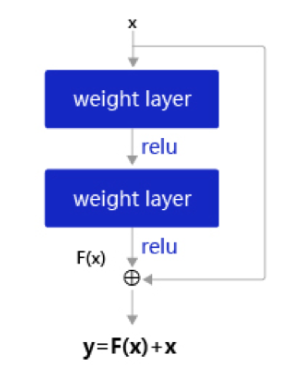
</div>

<center>图2 残差单元结构</center>

# 2.3 模型构建

一个残差网络通常有很多个残差单元堆叠而成。下面我们来构建一个在计算机视觉中非常典型的残差网络：ResNet18，并用ResNet18实现手写体数字识别任务。

下面我们先构建ResNet18的残差单元，然后再组建完整的网络。

### 2.3.1 残差单元

这里，我们实现一个算子`ResBlock`来构建残差单元，其中定义了`use_residual`参数，用于在后续实践中控制是否使用残差连接。


*******

残差单元包裹的非线性层的输入和输出形状大小应该一致。如果一个卷积层的输入特征图和输出特征图的通道数不一致，则其输出与输入特征图无法直接相加。为了解决上述问题，我们可以使用$1 \times 1$大小的卷积将输入特征图的通道数映射为与级联卷积输出特征图的一致通道数。

$1 \times 1$卷积：与标准卷积完全一样，唯一的特殊点在于卷积核的尺寸是$1 \times 1$，也就是不去考虑输入数据局部信息之间的关系，而把关注点放在不同通道间。通过使用$1 \times 1$卷积，可以起到如下作用：

* 实现信息的跨通道交互与整合。考虑到卷积运算的输入输出都是3个维度（宽、高、多通道），所以$1 \times 1$卷积实际上就是对每个像素点，在不同的通道上进行线性组合，从而整合不同通道的信息；
* 对卷积核通道数进行降维和升维，减少参数量。经过$1 \times 1$卷积后的输出保留了输入数据的原有平面结构，通过调控通道数，从而完成升维或降维的作用；
* 利用$1 \times 1$卷积后的非线性激活函数，在保持特征图尺寸不变的前提下，大幅增加非线性。

*******

In [ ]:
import paddle.nn as nn
class ResBlock(nn.Layer):
    def __init__(self, in_channels, out_channels, stride=1, use_residual=True):
        """
        残差单元
        输入：
            - in_channels：输入通道数
            - out_channels：输出通道数
            - stride：残差单元的步长，通过调整残差单元中第一个卷积层的步长来控制
            - use_residual：用于控制是否使用残差连接
        """
        super(ResBlock, self).__init__()
        self.stride = stride
        self.use_residual = use_residual
        # 第一个卷积层，卷积核大小为3×3，可以设置不同输出通道数以及步长
        self.conv1 = nn.Conv2D(in_channels, out_channels, 3, padding=1, stride=self.stride, bias_attr=False)
        # 第二个卷积层，卷积核大小为3×3，不改变输入特征图的形状，步长为1
        self.conv2 = nn.Conv2D(out_channels, out_channels, 3, padding=1, bias_attr=False)
        
        # 如果conv2的输出和此残差块的输入数据形状不一致，则use_1x1conv = True
        # 当use_1x1conv = True，添加1个1x1的卷积作用在输入数据上，使其形状变成跟conv2一致
        if in_channels != out_channels or stride != 1:
            self.use_1x1conv = True
        else:
            self.use_1x1conv = False
        # 当残差单元包裹的非线性层输入和输出通道数不一致时，需要用1×1卷积调整通道数后再进行相加运算
        if self.use_1x1conv:
            self.shortcut = nn.Conv2D(in_channels, out_channels, 1, stride=self.stride, bias_attr=False)

        # 每个卷积层后会接一个批量规范化层，批量规范化的内容在7.5.1中会进行详细介绍
        self.bn1 = nn.BatchNorm2D(out_channels)
        self.bn2 = nn.BatchNorm2D(out_channels)
        if self.use_1x1conv:
            self.bn3 = nn.BatchNorm2D(out_channels)

    def forward(self, inputs):
        y = F.relu(self.bn1(self.conv1(inputs)))
        y = self.bn2(self.conv2(y))
        if self.use_residual:   # 如果启用残差连接
            if self.use_1x1conv:  # 如果为真，对inputs进行1×1卷积，将形状调整成跟conv2的输出y一致
                shortcut = self.shortcut(inputs)
                shortcut = self.bn3(shortcut)
            else: # 否则直接将inputs和conv2的输出y相加
                shortcut = inputs
            y = paddle.add(shortcut, y)
        out = F.relu(y)
        return out

### 2.3.2 残差网络的整体结构

残差网络就是将很多个残差单元串联起来构成的一个非常深的网络。ResNet18 的网络结构如**图3**所示。

<center><img src="https://ai-studio-static-online.cdn.bcebos.com/16cb9fe0d0704940a829be1722fd6273b85209f198d143efb221f760d5f87f64" width = "700"></center>
<center><br>图3：残差网络</br></center>

其中为了便于理解，可以将ResNet18网络划分为6个模块：

* 第一模块：包含了一个步长为2，大小为$7 \times 7$的卷积层，卷积层的输出通道数为64，卷积层的输出经过批量归一化、ReLU激活函数的处理后，接了一个步长为2的$3 \times 3$的最大汇聚层；
* 第二模块：包含了两个残差单元，经过运算后，输出通道数为64，特征图的尺寸保持不变；
* 第三模块：包含了两个残差单元，经过运算后，输出通道数为128，特征图的尺寸缩小一半；
* 第四模块：包含了两个残差单元，经过运算后，输出通道数为256，特征图的尺寸缩小一半；
* 第五模块：包含了两个残差单元，经过运算后，输出通道数为512，特征图的尺寸缩小一半；
* 第六模块：包含了一个全局平均汇聚层，将特征图变为$1 \times 1$的大小，最终经过全连接层计算出最后的输出。

ResNet18模型的代码实现如下：

定义模块一。

In [ ]:
def make_first_module(in_channels):
    # 模块一：7*7卷积、批量规范化、汇聚
    m1 = nn.Sequential(nn.Conv2D(in_channels, 64, 7, stride=2, padding=3),
                    nn.BatchNorm2D(64), nn.ReLU(),
                    nn.MaxPool2D(kernel_size=3, stride=2, padding=1))
    return m1

定义模块二到模块五。

In [ ]:
def resnet_module(input_channels, out_channels, num_res_blocks, stride=1, use_residual=True):
    blk = []
    # 根据num_res_blocks，循环生成残差单元
    for i in range(num_res_blocks):
        if i == 0: # 创建模块中的第一个残差单元
            blk.append(ResBlock(input_channels, out_channels,
                                stride=stride, use_residual=use_residual))  # stride控制分辨率
        else:      # 创建模块中的其他残差单元
            blk.append(ResBlock(out_channels, out_channels, use_residual=use_residual))
    return blk

封装模块二到模块五。

In [ ]:
def make_modules(use_residual):
    # 模块二：包含两个残差单元，输入通道数为64，输出通道数为64，步长为1，特征图大小保持不变
    m2 = nn.Sequential(*resnet_module(64, 64, 2, stride=1, use_residual=use_residual))  # 2个残差块，4个卷积层
    # 模块三：包含两个残差单元，输入通道数为64，输出通道数为128，步长为2，特征图大小缩小一半。
    m3 = nn.Sequential(*resnet_module(64, 128, 2, stride=2, use_residual=use_residual))  # 2个残差块，4个卷积层
    # 模块四：包含两个残差单元，输入通道数为128，输出通道数为256，步长为2，特征图大小缩小一半。
    m4 = nn.Sequential(*resnet_module(128, 256, 2, stride=2, use_residual=use_residual))  # 2个残差块，4个卷积层
    # 模块五：包含两个残差单元，输入通道数为256，输出通道数为512，步长为2，特征图大小缩小一半。
    m5 = nn.Sequential(*resnet_module(256, 512, 2, stride=2, use_residual=use_residual))  # 2个残差块，4个卷积层
    return m2, m3, m4, m5

定义完整网络。

In [ ]:
# 定义完整网络
class Model_ResNet18(nn.Layer):
    def __init__(self, in_channels=3, num_classes=10, use_residual=True):
        super(Model_ResNet18,self).__init__()
        m1 = make_first_module(in_channels)  # 包含1个卷积层
        m2, m3, m4, m5 = make_modules(use_residual)  # 各包含4个卷积层，共16个卷积层
        # 封装模块一到模块6
        self.net = nn.Sequential(m1, m2, m3, m4, m5,
                        # 模块六：汇聚层、全连接层
                        nn.AdaptiveAvgPool2D(1), nn.Flatten(), nn.Linear(512, num_classes) )  # 最后1个全连接层

    def forward(self, x):
        return self.net(x)

这里同样可以使用`paddle.summary`统计模型的参数量。

In [ ]:
model = Model_ResNet18(in_channels=1, num_classes=10, use_residual=True)
params_info = paddle.summary(model, (1, 1, 32, 32))
print(params_info)

使用`paddle.flops`统计模型的计算量。

In [ ]:
FLOPs = paddle.flops(model, (1, 1, 32, 32), print_detail=True)
print(FLOPs)

# 3.模型训练

接下来，用一个循环来进行模型的训练，将会:
* 使用 `paddle.io.DataLoader` 来加载数据并组建batch。
* 使用 `F.cross_entropy` 来计算损失值。
* 使用 `paddle.optimizer.SGD` 优化器来进行优化。


用DataLoader对数据集进行封装

In [ ]:
# 批次大小
batch_size = 32
# 加载数据
train_loader = io.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
dev_loader = io.DataLoader(dev_dataset, batch_size=batch_size)
test_loader = io.DataLoader(test_dataset, batch_size=batch_size)
# 以下代码用于查看一个批次数据
iter_test_loader = iter(test_loader)
X, label = next(iter_test_loader)
print(X.shape)
print(label)

In [ ]:
import paddle.optimizer as opt
import paddle.nn.functional as F

# 学习率大小
lr = 0.01  
# 定义网络，通过指定use_residual为True，使用残差结构的深层网络
model = Model_ResNet18(in_channels=1, num_classes=10, use_residual=True)
# 定义损失函数。softmax+交叉熵
loss_fn = F.cross_entropy
# 定义优化器
optimizer = opt.SGD(learning_rate=lr, parameters=model.parameters())

# 初始化记录列表
train_losses = []        # 记录每训练1个epoch后，模型在整个训练集上的平均损失
train_step_losses = []   # 记录每训练1个step后，模型在该batch训练数据上的平均损失
val_losses = []          # 记录每训练1个step后进行验证时，模型在验证集上的平均损失        
val_accuracies = []      # 记录每训练1个step后进行验证时，模型在验证集上的精度

# 训练模型：使用训练集和验证集进行模型训练，共训练20个epoch。保存准确率最高的模型作为最佳模型。
num_epochs = 20
best_accuracy = 0.0
best_model_state = None
# 模型保存路径
model_path = "best_model.pdparams"

使用训练集和验证集进行模型训练，共训练20个epoch。在实践中，保存准确率最高的模型作为最佳模型。代码实现如下：

In [ ]:
# 每个step（即每个batch）训练后用验证集进行验证并保留最好的
global_step = 0
# 训练总的步数
num_training_steps = num_epochs * len(train_loader)   # len(train_loader)是batch的数量
log_steps = 15      # 每log_steps个step输出一次训练信息
eval_steps = 15     # 每eval_steps个step输出一次验证信息
# 启动训练
for epoch in range(num_epochs):
    # 训练阶段
    model.train()
    train_epoch_loss = 0.0
    for batch_idx, (X_batch, y_batch) in enumerate(train_loader):
        optimizer.clear_grad()
        predictions = model(X_batch)
        y_batch = paddle.cast(y_batch, dtype='int64')
        train_loss = loss_fn(predictions, y_batch)
        train_step_losses.append(train_loss.item())  # 记录每个step的损失
        train_loss.backward()
        optimizer.step()
        train_epoch_loss += train_loss.item()
        if global_step%log_steps==0:   # 每训练15个step输出一下信息
            print(f"[Train] epoch: {epoch}/{num_epochs}, step: {global_step}/{num_training_steps}, loss: {train_loss.item():.5f}")
        global_step += 1
        
        # 验证阶段
        model.eval()
        val_epoch_loss = 0.0
        correct = 0
        total = 0
        with paddle.no_grad():
            for X_batch, y_batch in dev_loader:
                val_predictions = model(X_batch)
                y_batch = paddle.cast(y_batch, dtype='int64')
                val_loss = loss_fn(val_predictions, y_batch)
                val_epoch_loss += val_loss.item()
                val_pred_class = paddle.argmax(val_predictions, axis=1)
                correct += (val_pred_class == y_batch).sum().item()
                total += len(y_batch)
                
        # 计算平均验证损失和准确率
        val_epoch_loss /= len(dev_loader)
        val_accuracy = correct / total
        val_losses.append(val_epoch_loss)
        val_accuracies.append(val_accuracy)
        if global_step%eval_steps==0:   # 每训练15个step输出一下验证信息 
            print(f"[Evaluate]  val score: {val_accuracy:.5f}, val loss: {val_epoch_loss:.5f}") 

        # 保存最佳模型
        if val_accuracy > best_accuracy:
            best_model_state = model.state_dict()
            print(f"[Evaluate] best accuracy performence has been updated: {best_accuracy:.5f} --> {val_accuracy:.5f}")
            best_accuracy = val_accuracy
            best_model_state = model.state_dict()
            paddle.save(best_model_state, model_path)
        
    
    # 计算平均训练损失
    train_epoch_loss /= len(train_loader)
    train_losses.append(train_epoch_loss)

    

可视化观察训练集损失和训练集loss变化情况。

In [ ]:
import matplotlib.pyplot as plt

# 绘制损失变化曲线
plt.figure(figsize=(10, 5))
# 抽样显示每20个数据点中的第一个数据点
sample_train_losses = train_step_losses[::20]
sample_val_losses = val_losses[::20]
# 对应的step
sample_indices_train = range(0, len(train_step_losses), 20)
sample_indices_val = range(0, len(val_losses), 20)
# 绘制step的曲线
plt.plot(sample_indices_train, sample_train_losses, color="#e4007f", linestyle="-", label='Train Loss')
plt.plot(sample_indices_val, sample_val_losses, color='#f19ec2', linestyle="--", label='Val Loss')
plt.title('Training and Validation Loss Over Steps')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 绘制验证集上的准确率变化曲线
plt.figure(figsize=(10, 5))
# 抽样显示每20个数据点中的第一个数据点
sample_val_accuracies = val_accuracies[::20]
# 对应的step
sample_indices_val = range(0, len(val_accuracies), 20)
plt.plot(sample_indices_val, sample_val_accuracies, color='#f19ec2', linestyle="--", label='Validation Accuracy')
plt.title('Validation Accuracy Over Steps')
plt.xlabel('Step')
plt.ylabel('Accuracy')
plt.legend()
# 设置Y轴的范围从0到1
plt.ylim(0, 1.2)
plt.show()

# 4. 模型评价

使用测试数据对在训练过程中保存的最佳模型进行评价，观察模型在测试集上的准确率以及Loss情况。代码实现如下：

In [ ]:
import os
# 加载最佳模型
if os.path.exists(model_path):
    model.load_dict(paddle.load(model_path))
    
# 测试模型
model.eval()
test_epoch_loss = 0.0
correct = 0
total = 0
with paddle.no_grad():
    for X_batch, y_batch in test_loader:
        test_predictions = model(X_batch)
        y_batch = paddle.cast(y_batch, dtype='int64')
        test_loss = loss_fn(test_predictions, y_batch)
        test_epoch_loss += test_loss.item()
        test_pred_class = paddle.argmax(test_predictions, axis=1)
        print("test_pred_class:", test_pred_class)
        print("labels:", y_batch)
        correct += paddle.sum(test_pred_class == y_batch).item()
        total += len(y_batch)
    
# 计算平均测试损失和准确率
test_epoch_loss /= len(test_loader)
test_accuracy = correct / total
print(f"Test Accuracy: {test_accuracy:.2f}, Test Loss: {test_epoch_loss:.4f}")